# Task 1 · Notebook 03 — Sentiment Model

**Goal.** Build a model that reads a review title and predicts whether the passenger had a positive or negative experience.

**Where the labels come from.** Each passenger also gave star ratings, so their own average rating tells us how they felt. Reviews averaging 2.5 stars or less are labelled *negative*, and 3.5 or more *positive*. Reviews in between are left out because they are genuinely mixed.

**Why this matters.** The original version of this project labelled reviews with VADER and then trained a model to predict VADER's labels from VADER's own score. That is circular, which is why it reported a meaningless 100% accuracy. Here the labels come from the passengers, and VADER becomes a baseline the model has to beat.

**Final model.** The notebook first builds a text-only model. A stress test later revealed a weakness, so Experiment 2 (at the end) replaces it with a **hybrid TF-IDF + VADER model**, which is the one saved and used by the app.

**Data used.** Only reviews with an informative title (Notebook 01) and at least 3 star ratings, so each label rests on a reasonable amount of evidence.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLEAN_FILE = Path("data/processed/reviews_clean.csv")
MODEL_DIR = Path("models")

df = pd.read_csv(CLEAN_FILE, parse_dates=["date_flown"])
print(f"Loaded {len(df):,} cleaned reviews")

Loaded 4,015 cleaned reviews


In [2]:
# Keep reviews whose title is the passenger's own words and that carry enough ratings to trust
data = df[df["has_informative_title"] & (df["n_ratings"] >= 3)].copy()

# Label from the passenger's own average rating
data["label"] = np.select(
    [data["avg_rating"] <= 2.5, data["avg_rating"] >= 3.5],
    [0, 1],                       # 0 = negative, 1 = positive
    default=-1,                   # -1 = mixed, excluded below
)

print("Before removing mixed reviews:")
print(data["label"].value_counts().rename({0: "negative", 1: "positive", -1: "mixed"}))

data = data[data["label"] != -1]
print(f"\nReviews available for modelling: {len(data):,}")

Before removing mixed reviews:
label
negative    1466
positive     888
mixed        572
Name: count, dtype: int64

Reviews available for modelling: 2,354


In [3]:
for label, name in [(0, "NEGATIVE"), (1, "POSITIVE")]:
    print(f"{name} examples")
    sample = data[data["label"] == label].sample(5, random_state=1)
    for title, rating in zip(sample["review_title"], sample["avg_rating"]):
        print(f"{rating:.1f} stars  |  {title}")
    print()

NEGATIVE examples
1.2 stars  |  how things have changed
1.4 stars  |  Air conditioning problem
1.5 stars  |  offered me no compensation
1.6 stars  |  declined due to cost cutting
2.2 stars  |  service poorly synchronised

POSITIVE examples
4.0 stars  |  has been hit by cost savings
4.0 stars  |  Staff on both flights fine
3.8 stars  |  good hand baggage only deal
3.6 stars  |  all in all decent flights
4.5 stars  |  unlimited legroom and a speedy exit



In [4]:
from sklearn.model_selection import train_test_split

X = data["review_title"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training reviews: {len(X_train):,}   Test reviews: {len(X_test):,}")
print(f"Share positive in train {y_train.mean():.1%}, in test {y_test.mean():.1%}")

Training reviews: 1,883   Test reviews: 471
Share positive in train 37.7%, in test 37.8%


In [5]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

analyzer = SentimentIntensityAnalyzer()
vader_score = X_test.apply(lambda t: analyzer.polarity_scores(t)["compound"])
vader_pred = (vader_score >= 0.05).astype(int)   # VADER's standard cut-off for "positive"

print(f"VADER accuracy:  {accuracy_score(y_test, vader_pred):.3f}")
print(f"VADER macro F1:  {f1_score(y_test, vader_pred, average='macro'):.3f}")
print(f"VADER ROC AUC:   {roc_auc_score(y_test, vader_score):.3f}")
print(f"Titles VADER scores as neutral (no sentiment words): {(vader_score.abs() < 0.05).mean():.0%}")

VADER accuracy:  0.809
VADER macro F1:  0.792
VADER ROC AUC:   0.872
Titles VADER scores as neutral (no sentiment words): 31%


In [6]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = Pipeline([
    ("features", FeatureUnion([
        # Whole words and two-word phrases, e.g. "no compensation", "legroom"
        ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        # Pieces of words (2–5 letters), which cope with typos and word endings like "delay"/"delayed"
        ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    ])),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", C=2)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")

print("Macro F1 on each of the 5 folds:", cv_scores.round(3))
print(f"Average: {cv_scores.mean():.3f} (± {cv_scores.std():.3f})")

Macro F1 on each of the 5 folds: [0.815 0.785 0.804 0.808 0.819]
Average: 0.806 (± 0.012)


In [7]:
model.fit(X_train, y_train)

model_pred = model.predict(X_test)
model_proba = model.predict_proba(X_test)[:, 1]   # probability of "positive"

comparison = pd.DataFrame({
    "VADER (word dictionary)": [
        accuracy_score(y_test, vader_pred),
        f1_score(y_test, vader_pred, average="macro"),
        roc_auc_score(y_test, vader_score),
    ],
    "Text-only (TF-IDF + logistic regression)": [
        accuracy_score(y_test, model_pred),
        f1_score(y_test, model_pred, average="macro"),
        roc_auc_score(y_test, model_proba),
    ],
}, index=["Accuracy", "Macro F1", "ROC AUC"]).round(3)

comparison

,VADER (word dictionary),Text-only (TF-IDF + logistic regression)
Accuracy,0.809,0.864
Macro F1,0.792,0.856
ROC AUC,0.872,0.912


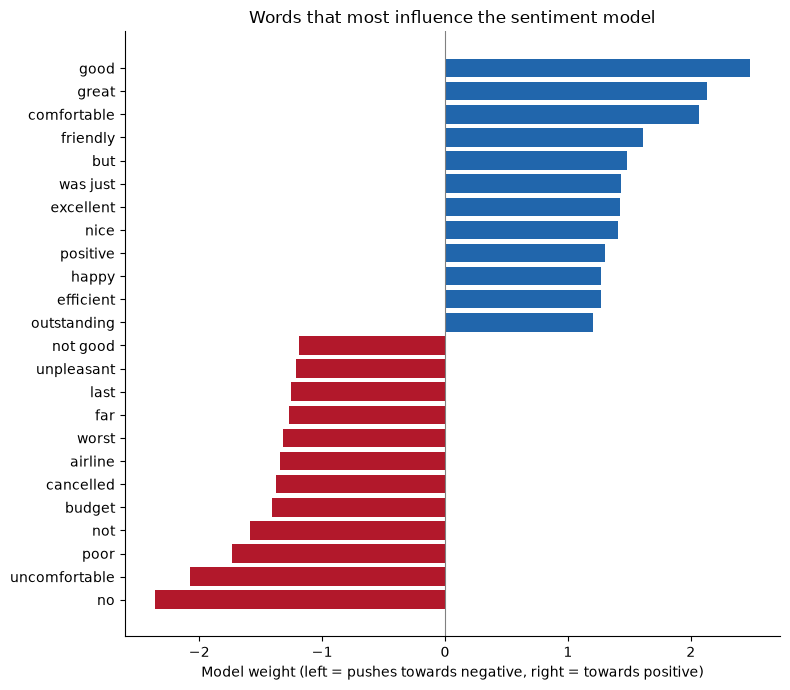

In [8]:
# The word features come first inside the FeatureUnion, so the first N weights belong to words
word_vectorizer = model.named_steps["features"].transformer_list[0][1]
word_names = word_vectorizer.get_feature_names_out()
word_weights = model.named_steps["classifier"].coef_[0][: len(word_names)]

weights = pd.Series(word_weights, index=word_names).sort_values()
top = pd.concat([weights.head(12), weights.tail(12)])

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#b2182b" if w < 0 else "#2166ac" for w in top]   # red = negative, blue = positive
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Model weight (left = pushes towards negative, right = towards positive)")
ax.set_title("Words that most influence the sentiment model")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import confusion_matrix

results = pd.DataFrame({"title": X_test, "true_label": y_test, "prob_positive": model_proba})
results["predicted"] = (results["prob_positive"] >= 0.5).astype(int)
errors = results[results["predicted"] != results["true_label"]].copy()

# How confident was the model when it was wrong? (0.5 = unsure, 0 or 1 = very sure)
errors["confidence"] = (errors["prob_positive"] - 0.5).abs()

print(f"Errors: {len(errors)} of {len(results)} test reviews\n")
print(pd.DataFrame(confusion_matrix(y_test, results["predicted"]),
                   index=["actually negative", "actually positive"],
                   columns=["predicted negative", "predicted positive"]))

print("\nMost confident mistakes:")
errors.sort_values("confidence", ascending=False).head(10)[["title", "true_label", "prob_positive"]]

Errors: 64 of 471 test reviews

                   predicted negative  predicted positive
actually negative                 261                  32
actually positive                  32                 146

Most confident mistakes:


,title,true_label,prob_positive
138,"no fuss, no bother experience",1,0.022648
2500,no one climbing over you,1,0.060885
614,cabin crew were very helping,0,0.938933
3057,other budget airlines better wake up,1,0.065422
2652,absolutely no complaints,1,0.081262
1686,One issue after another!,1,0.112216
1536,once again disappointed,1,0.123258
1039,seat are surprisingly comfortable,0,0.867631
1563,service was outstanding,0,0.862753
2920,FA's showed no enthusiasm,1,0.141651


## Results

| | VADER (word dictionary) | Text-only model (TF-IDF + logistic regression) |
|---|---|---|
| Accuracy | 0.809 | **0.864** |
| Macro F1 | 0.792 | **0.856** |
| ROC AUC | 0.872 | **0.912** |

Cross-validated macro F1 on the training set was 0.806 (± 0.012), so a realistic expectation for this text-only model on new reviews is roughly 0.80–0.86. (The final hybrid model is evaluated in Experiment 2.)

**What the model learned.** Sensible airline language, such as *good, comfortable, friendly* versus *uncomfortable, poor, cancelled*. It also picked up simple negation ("not good") and domain patterns VADER cannot know, for example *budget* signalling a negative comparison with low-cost airlines.

**Error analysis (64 of 471 test reviews wrong).** The mistakes fall into two groups.
1. **Genuine model limitations.** Positive phrases built from negative words ("no fuss, no bother", "absolutely no complaints") are misread because the model weighs words largely on their own.
2. **Label noise.** Some titles contradict the passenger's overall rating ("One issue after another!" from a satisfied passenger, "service was outstanding" from a dissatisfied one). A title describes one moment, while the ratings cover the whole trip. Here the model often reads the text correctly.

**Limitations.** Titles are short (often 3–6 words), and only 2,354 reviews could be labelled with confidence. A model trained on full review text would likely do better, but that text could not be collected (see Notebook 01).

## Experiment: can negation handling fix the "no complaints" errors?

**Hypothesis.** The model misreads positive phrases such as "no complaints" because it scores "no" and "complaints" separately. Treating a negation word plus the following word as a single token ("no complaints", "not good") should let the model learn these phrases as units.

**Method.** Compare the current model with a negation-aware version using 5-fold cross-validation on the training set only. The test set is not used to choose between them, to avoid tuning the model to it.

In [10]:
# A token is either "negation word + next word" (e.g. "no complaints") or a normal single word
NEGATION_TOKENS = r"(?u)\b(?:no|not|never|nothing|without)\s+\w+\b|\b\w\w+\b"

print("How the new tokenizer splits a title:")
print(TfidfVectorizer(token_pattern=NEGATION_TOKENS).build_analyzer()("Absolutely no complaints, not good at all"))

negation_model = Pipeline([
    ("features", FeatureUnion([
        ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  token_pattern=NEGATION_TOKENS)),
        ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    ])),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", C=2)),
])

neg_scores = cross_val_score(negation_model, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"\nCurrent model   CV macro F1: {cv_scores.mean():.3f} (± {cv_scores.std():.3f})")
print(f"Negation model  CV macro F1: {neg_scores.mean():.3f} (± {neg_scores.std():.3f})")

# Does it fix the specific phrases we saw?
negation_model.fit(X_train, y_train)
phrases = ["no fuss, no bother experience", "absolutely no complaints", "not bad at all"]
pd.DataFrame({
    "current model": model.predict_proba(phrases)[:, 1],
    "negation model": negation_model.predict_proba(phrases)[:, 1],
}, index=phrases).round(2).rename_axis("probability of positive")

How the new tokenizer splits a title:
['absolutely', 'no complaints', 'not good', 'at', 'all']

Current model   CV macro F1: 0.806 (± 0.012)
Negation model  CV macro F1: 0.806 (± 0.018)


,current model,negation model
probability of positive,,
"no fuss, no bother experience",0.02,0.14
absolutely no complaints,0.08,0.20
not bad at all,0.11,0.08


In [11]:
phrase_pattern = r"\bno (?:complaints|fuss|problems?|issues)\b|\bnot bad\b"
matches = X_train[X_train.str.lower().str.contains(phrase_pattern)]

print(f"Training titles containing these phrases: {len(matches)} of {len(X_train):,}")
matches.tolist()

Training titles containing these phrases: 1 of 1,883


['all in all not bad']

**Result.** The negation-aware model scored the same in cross-validation (macro F1 0.806 for both). Two of the three problem phrases moved slightly towards positive, but all three were still misclassified.

**Why it did not work.** These phrases are extremely rare in the training data, so the model has almost no examples to learn their meaning from. Splitting the text differently cannot make up for missing examples.

**Decision.** Keep the original, simpler model. When two models perform the same, the simpler one is preferred because it is easier to explain and maintain.

*(This decision was later revised. See Experiment 2, where a stress test led to the hybrid model that the app uses.)*

**What would help.** More labelled data, or a pre-trained language model (such as BERT) that has already learned from billions of sentences that "no complaints" is praise.

In [12]:
# Fit the text-only model on ALL labelled reviews (train + test).
# It is used for comparison in Experiment 2. The model saved for the app is the hybrid, at the end.
final_model = model.fit(X, y)

print("Check:", final_model.predict_proba(["the crew were wonderful", "never flying BA again"])[:, 1].round(2))

Check: [0.96 0.07]


## Experiment 2: a stress test reveals a weakness

When the model was tried in the Streamlit app, the title **"The crew was crap"** was scored as 87% positive. The cells below investigate why, and test a fix.

In [13]:
stress_tests = ["The crew was crap", "the crew was awful", "the crew were rude", "food was crap",
                "no complaints at all", "the crew was rubbish", "seat was cramped but staff were lovely",
                "the crew were wonderful"]
display(pd.DataFrame({"chance positive": final_model.predict_proba(stress_tests)[:, 1].round(2)},
                     index=stress_tests))

titles = X.str.lower()
crew = titles.str.contains(r"\bcrew\b")
print(f"Titles mentioning 'crew': {crew.sum()}, of which positive: {y[crew].mean():.0%}")
print(f"Titles containing 'crap': {titles.str.contains('crap').sum()}")

,chance positive
The crew was crap,0.87
the crew was awful,0.49
the crew were rude,0.76
food was crap,0.69
no complaints at all,0.49
the crew was rubbish,0.81
seat was cramped but staff were lovely,0.81
the crew were wonderful,0.96


Titles mentioning 'crew': 148, of which positive: 83%
Titles containing 'crap': 0


**Diagnosis**
- **Unseen words are ignored.** No training title contains "crap", so the model has no idea it is negative.
- **Topic is mistaken for sentiment.** 148 titles mention the crew and 83% of them are positive, because crew are BA's best-rated service area. The model learned that "crew" signals a positive review, a **spurious correlation** between topic and label.

The test-set score did not reveal this because test reviews follow the same patterns as training reviews. Free text typed into the app does not.

**Proposed fix: a hybrid model.** VADER knows thousands of emotional words but nothing about airlines. Our model knows airline language but learned from only 2,354 short titles. Adding VADER's score as an extra input lets the model combine both. This is not circular, because the labels still come from passengers' star ratings and VADER is only one input among many.

In [14]:
from sklearn.compose import ColumnTransformer

# Settings (text weight 0.5, C=1) were chosen by trying a few combinations with cross-validation on the
# training set, together with the stress tests above. The test set was not used to choose them.

def with_vader(titles):
    """Turn a list of titles into the two inputs the hybrid model needs: the text and its VADER score."""
    titles = pd.Series(list(titles))
    return pd.DataFrame({"title": titles,
                         "vader": [analyzer.polarity_scores(t)["compound"] for t in titles]})

hybrid = Pipeline([
    ("features", ColumnTransformer([
        ("text", FeatureUnion([
            ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
        ]), "title"),
        ("vader", "passthrough", ["vader"]),
    ], transformer_weights={"text": 0.5, "vader": 1.0})),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", C=1)),
])

Xh_train, Xh_test = with_vader(X_train), with_vader(X_test)
hybrid_cv = cross_val_score(hybrid, Xh_train, y_train.to_numpy(), cv=cv, scoring="f1_macro")
print(f"Original model  CV macro F1: {cv_scores.mean():.3f} (± {cv_scores.std():.3f})")
print(f"Hybrid model    CV macro F1: {hybrid_cv.mean():.3f} (± {hybrid_cv.std():.3f})")

hybrid.fit(Xh_train, y_train.to_numpy())
hybrid_proba = hybrid.predict_proba(Xh_test)[:, 1]
comparison["Hybrid (TF-IDF + VADER score)"] = [
    accuracy_score(y_test, hybrid_proba >= 0.5),
    f1_score(y_test, hybrid_proba >= 0.5, average="macro"),
    roc_auc_score(y_test, hybrid_proba),
]
comparison.round(3)

Original model  CV macro F1: 0.806 (± 0.012)
Hybrid model    CV macro F1: 0.820 (± 0.011)


,VADER (word dictionary),Text-only (TF-IDF + logistic regression),Hybrid (TF-IDF + VADER score)
Accuracy,0.809,0.864,0.845
Macro F1,0.792,0.856,0.836
ROC AUC,0.872,0.912,0.914


In [15]:
stress = pd.DataFrame({
    "original model": final_model.predict_proba(stress_tests)[:, 1],
    "hybrid model": hybrid.predict_proba(with_vader(stress_tests))[:, 1],
}, index=stress_tests).round(2)
stress

,original model,hybrid model
The crew was crap,0.87,0.29
the crew was awful,0.49,0.16
the crew were rude,0.76,0.23
food was crap,0.69,0.23
no complaints at all,0.49,0.67
the crew was rubbish,0.81,0.60
seat was cramped but staff were lovely,0.81,0.95
the crew were wonderful,0.96,0.93


**Result**

| | Original | Hybrid |
|---|---|---|
| CV macro F1 (5 folds) | 0.806 ± 0.012 | **0.820 ± 0.011** |
| Test macro F1 (471 reviews) | **0.856** | 0.836 |
| Test ROC AUC | 0.912 | **0.914** |

The hybrid scores higher in cross-validation, slightly lower on test macro F1, and about the same on ROC AUC. With only 471 test reviews these differences are within normal variation, so on the standard measures the two models are roughly equal.

The stress tests separate them clearly. The hybrid correctly reads unseen insults ("crap") and negative remarks about the crew ("rude", "awful"), and even gets "no complaints at all" right, which the negation experiment could not fix.

**Decision.** Use the hybrid model. It performs as well on the standard measures and generalises far better to the free text people type into the app.

**Remaining limitation.** "the crew was rubbish" is still misread, because neither VADER nor the training data knows that British slang word.

**Caveat.** The same stress sentences were also used when choosing the hybrid's settings, so they illustrate the fix rather than measure it independently. The cross-validation and test scores above are the independent measures.

**Lesson.** A good test score does not guarantee sensible behaviour on new kinds of input. Stress-testing a model with hand-written cases revealed a spurious correlation that standard evaluation missed.

In [16]:
import json
import joblib
import sklearn
from datetime import date

# Final model for the app: the hybrid, trained on ALL labelled reviews
final_hybrid = hybrid.fit(with_vader(X), y.to_numpy())
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(final_hybrid, MODEL_DIR / "sentiment_model.joblib")

model_info = {
    "description": "Hybrid: TF-IDF (words + character n-grams) on the title plus the VADER compound score, "
                   "combined in a logistic regression",
    "input": "a DataFrame with columns 'title' (text) and 'vader' (VADER compound score of the title)",
    "label_rule": "negative if average star rating <= 2.5, positive if >= 3.5",
    "trained_on_reviews": int(len(X)),
    "trained_date": str(date.today()),
    "scikit_learn_version": sklearn.__version__,
    "cv_macro_f1": round(float(hybrid_cv.mean()), 3),
    "cv_macro_f1_original_model": round(float(cv_scores.mean()), 3),
    "test_results": comparison.round(3).to_dict(),
}
(MODEL_DIR / "sentiment_model_info.json").write_text(json.dumps(model_info, indent=2))

print("Saved hybrid model to", MODEL_DIR)
print("Check:", final_hybrid.predict_proba(with_vader(["The crew was crap", "the crew were wonderful"]))[:, 1].round(2))

Saved hybrid model to models
Check: [0.32 0.94]
